In [1]:
import numpy as np
import RandomTilings as RT
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from time import perf_counter as time
from time import sleep
RT.config.log_variant = 1

# Pixel Plot

In [2]:
from numba import njit, prange
from functools import lru_cache


def aztec_image(M, fac=1, *, parallel=False):
    # Return an int8 image, row 0 at the top; no plotting objects created.
    M = np.asarray(M)
    if M.ndim != 2 or M.shape[0] != M.shape[1] or M.shape[0] % 2:
        raise ValueError('M must be a square matrix with even side length')
    if M.dtype.kind not in 'biu':
        raise TypeError('M must contain integers or booleans')
    if isinstance(fac, (bool, np.bool_)) or not isinstance(fac, (int, np.integer)) or fac < 1:
        raise ValueError('fac must be a positive integer')
    # Reuse the usual int8 edge matrix without allocating an active-edge copy.
    if M.dtype != np.int8 and M.dtype != np.bool_:
        M = M == 1
    s = 2*int(fac)
    M = np.ascontiguousarray(M)
    offsets = _offsets(s, s*(len(M)+2))
    if parallel:
        # Finish zeroing before any thread stamps. This avoids concurrent
        # initialization/stamping, and all threads share this one array.
        side = s*(len(M)+2)
        image = np.zeros((side,side),dtype=np.int8)
        _fill_parallel(M,s,offsets,image.reshape(-1))
        return image
    return _stamp(M, s, offsets)


@njit(cache=True)
def _masks(s):
    # Two reusable masks, evaluated at pixel centers. s = 2*fac.
    masks = np.zeros((2, 3*s, 3*s), dtype=np.bool_)
    for r in range(3*s):
        for c in range(3*s):
            # Twice local coordinates in output pixels; v increases UP.
            u = 2*c + 1 - 3*s
            v = 3*s - 2*r - 1
            a, b = u+v, u-v
            # Moving upward increases a and decreases b.
            # Thus a's upper bound and b's lower bound are EXCLUDED.
            # A top edge stays background; a bottom edge gets this tile.
            masks[0,r,c] = (-2*s <= a < 2*s) and (-4*s < b <= 4*s)
            masks[1,r,c] = (-4*s <= a < 4*s) and (-2*s < b <= 2*s)
    return masks


@lru_cache(maxsize=8)
def _offsets(s, side):
    # Option 2: compute only the nonzero pixel positions, once per size/scale.
    # Flatten (row, column) into row*side + column to save address arithmetic.
    masks = _masks(s)
    offsets = np.empty((2, 4*s*s), dtype=np.intp)
    for shape in range(2):
        rows, cols = np.nonzero(masks[shape])
        offsets[shape] = rows*side + cols
    offsets.flags.writeable = False
    return offsets


@njit(cache=True)
def _stamp(M, s, offsets):
    L = M.shape[0]
    side = s*(L+2)
    image = np.zeros((side, side), dtype=np.int8)
    flat = image.reshape(side*side)  # View, not a copy.

    for y in range(L):
        for x in range(L):
            if M[y,x] != 1:
                continue
            shape = 0 if (x+y) % 2 else 1
            if x % 2:
                color = 1 if y % 2 == 0 else 2
            else:
                color = 3 if y % 2 else 4
            # Center: row=s*(y+1.5)-.5, col=s*(x+1.5)-.5.
            # The mask's top-left index is (s*y, s*x).
            base = s*y*side + s*x
            for k in range(offsets.shape[1]):
                flat[base + offsets[shape,k]] = color
    return image


@njit(inline='always')
def _put(flat, base, offsets, color):
    for k in range(offsets.size):
        flat[base+offsets[k]] = color


@njit(cache=True, parallel=True)
def _fill_parallel(M, s, offsets, flat):
    # Each task handles one row of 2x2 blocks. Numba batches those tasks
    # among its threads. Only this OUTER loop uses prange.
    # Requires a valid tiling: nonzero stamp pixels must be disjoint.
    L = M.shape[0]
    side = s*(L+2)
    down = s*side
    for block_row in prange(L//2):
        y = 2*np.int64(block_row)
        for x in range(0,L,2):
            base = s*y*side+s*x
            # Top-left, top-right, bottom-left, bottom-right:
            # shape/color are constants; only edge activity is tested.
            if M[y,x] == 1:
                _put(flat,base,offsets[1],4)
            if M[y,x+1] == 1:
                _put(flat,base+s,offsets[0],1)
            if M[y+1,x] == 1:
                _put(flat,base+down,offsets[0],3)
            if M[y+1,x+1] == 1:
                _put(flat,base+down+s,offsets[1],2)


def plot_aztec(M, fac=1, cmap = None, filename=None, parallel=False):
    # Return (4-by-4-inch figure, full-resolution int8 image).
    # The figure uses a fixed 100 DPI and has no axes margins. Its 400-by-400
    # display resamples the array using nearest-neighbor interpolation.
    # If filename is given, save a PNG at the original array resolution,
    # with DPI metadata for a 4-inch print size. View that PNG at 100% to
    # inspect every original pixel. Screen inches depend on the display,
    # operating-system scaling and notebook/browser zoom.
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap

    image = aztec_image(M, fac, parallel=parallel)
    if cmap == None:
        cmap = ['white', 'red', 'green', 'yellow', '#6666ff']
    cmap = ListedColormap(cmap)
    fig = plt.figure(figsize=(4, 4), dpi=100, layout='none')
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(image, origin='upper', interpolation='nearest',
              cmap=cmap, vmin=-0.5, vmax=4.5)
    ax.set_axis_off()
    if filename is not None:
        plt.imsave(filename, image, cmap=cmap, vmin=-0.5, vmax=4.5,
                   origin='upper', format='png', dpi=image.shape[1]/4)
    return fig, image


# Glauber

In [3]:
"""Checkerboard Aztec Glauber dynamics and partial Matplotlib redraws.

Requires NumPy and Matplotlib. Run this file for an order-1 example.
W, E are ORIGINAL edge weights, not the reduced shuffling arrays C, E.
An edge has weight W[i,j] * epsilon**E[i,j], epsilon -> 0+.
Inputs are copied; a valid initial tiling M is required.
Use a blitting GUI backend, e.g. QtAgg or TkAgg (not inline/ipympl).
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.image import AxesImage
from matplotlib.transforms import Bbox
from IPython.display import display


def comp_prop_log(w, x, y, z, ew, ex, ey, ez):
    """Library _core.comp_prop_log formula; w,x,y,z are LOG weights."""
    if ex + ey > ew + ez:
        return 0.0
    if ex + ey < ew + ez:
        return -np.inf
    return w + z - np.logaddexp(w + z, x + y)


def masks(fac):
    """The existing rasterizer's two masks, with the upward boundary rule."""
    s = 2 * fac
    r, c = np.indices((3*s, 3*s))
    u, v = 2*c + 1 - 3*s, 3*s - 2*r - 1
    a, b = u + v, u - v
    return ((-2*s <= a) & (a < 2*s) & (-4*s < b) & (b <= 4*s),
            (-4*s <= a) & (a < 4*s) & (-2*s < b) & (b <= 2*s))


class Glauber:
    def __init__(self, W, E, M, fac=1, seed=None, probability_log=comp_prop_log):
        """Optionally pass the library's actual _core.comp_prop_log callable."""
        W, E, M = np.asarray(W), np.asarray(E), np.asarray(M)
        if (M.ndim != 2 or M.shape[0] != M.shape[1] or
                M.shape[0] < 2 or M.shape[0] % 2 or
                W.shape != M.shape or E.shape != M.shape):
            raise ValueError('W, E, M must have the same nonempty 2n by 2n shape')
        if not np.all((M == 0) | (M == 1)):
            raise ValueError('M must contain 0 and 1')
        if np.iscomplexobj(W) or not np.all(np.isfinite(W)) or np.any(W < 0):
            raise ValueError('W must contain finite nonnegative real coefficients')
        if not np.all(np.isfinite(E)) or not np.all(E == np.floor(E)):
            raise ValueError('E must contain integer exponents')
        if np.any(np.abs(E) > 1_000_000_000):
            raise ValueError('Exponent magnitude must be at most 1e9')
        if isinstance(fac, bool) or not isinstance(fac, (int, np.integer)) or fac < 1:
            raise ValueError('fac must be a positive integer')
        self.M = M.astype(np.int8, copy=True)
        W = W.astype(float, copy=True)
        E = E.astype(np.int32, copy=True)
        # Same literal-zero normalization as _core.reduce_weight, without reduction.
        E[W == 0] += 1
        W[W == 0] = 1
        logW = np.log(W)
        self.rng = np.random.default_rng(seed)
        self.s = 2 * fac
        self.masks = masks(fac)
        side = self.s * (len(M) + 2)
        self.image = np.zeros((side, side), dtype=np.int8)
        for y, x in zip(*np.nonzero(self.M)):
            self.stamp(y, x)
        # Probabilities depend only on the fixed weights, so compute them once.
        self.groups = []
        for parity in (0, 1):
            yy, xx = np.meshgrid(np.arange(parity, len(M)-1, 2),
                                 np.arange(parity, len(M)-1, 2), indexing='ij')
            p = np.empty(yy.shape)
            for ij in np.ndindex(yy.shape):
                y, x = yy[ij], xx[ij]
                p[ij] = np.exp(probability_log(
                    logW[y,x], logW[y,x+1], logW[y+1,x], logW[y+1,x+1],
                    E[y,x], E[y,x+1], E[y+1,x], E[y+1,x+1]))
            self.groups.append((yy, xx, p))

    def stamp(self, y, x):
        s = self.s
        color = (1 if y % 2 == 0 else 2) if x % 2 else (3 if y % 2 else 4)
        shape = 0 if (x+y) % 2 else 1
        self.image[s*y:s*(y+3), s*x:s*(x+3)][self.masks[shape]] = color

    def step(self, parity=None):
        """One color batch; fair random color by default. Return dirty rectangles.

        Rectangles are (row_start, row_stop, col_start, col_stop).
        No parallel threads; NumPy processes the independent sites as a batch.
        """
        if parity is None:
            parity = int(self.rng.integers(2))
        if parity not in (0, 1):
            raise ValueError('parity must be 0 or 1')
        y, x, p = self.groups[parity]
        M = self.M
        a, b, c, d = M[y,x], M[y,x+1], M[y+1,x], M[y+1,x+1]
        flippable = (a == d) & (b == c) & (a != b)
        diagonal = self.rng.random(p.shape) < p
        changed = flippable & (diagonal != a)
        ys, xs, ds = y[changed], x[changed], diagonal[changed]
        M[ys,xs] = M[ys+1,xs+1] = ds
        M[ys,xs+1] = M[ys+1,xs] = ~ds
        rectangles = []
        for y, x, diagonal in zip(ys, xs, ds):
            if diagonal:
                self.stamp(y, x)
                self.stamp(y+1, x+1)
            else:
                self.stamp(y, x+1)
                self.stamp(y+1, x)
            s = self.s
            rectangles.append((s*y, s*(y+4), s*x, s*(x+4)))
        return rectangles

    def sweep(self):
        """Both colors, in a state-independent random order."""
        first = int(self.rng.integers(2))
        return self.step(first) + self.step(1-first)


class PatchViewer:
    def __init__(self, sampler):
        self.sampler = sampler
        self.fig = plt.figure(figsize=(4, 4), dpi=100, layout='none')
        self.ax = self.fig.add_axes([0, 0, 1, 1])
        if not self.fig.canvas.supports_blit:
            plt.close(self.fig)
            raise RuntimeError('Use a blitting GUI backend: %matplotlib qt or tk, not widget/inline')
        cmap = ListedColormap(['white', '#8b1220', '#c44510', '#cc9d1c', '#411e4e'])
        self.base = self.ax.imshow(sampler.image, origin='upper', cmap=cmap,
                                   vmin=-0.5, vmax=4.5, interpolation='nearest')
        # imshow owns a copy: make it the persistent array updated by the sampler.
        sampler.image = self.base.get_array().data
        self.ax.set_axis_off()
        self.ax.set_autoscale_on(False)
        self.patch = AxesImage(self.ax, origin='upper', cmap=cmap,
                               interpolation='nearest', animated=True)
        self.patch.set_clim(-0.5, 4.5)
        self.patch.set_data(np.zeros((1, 1), dtype=np.int8))
        # Saving can include animated artists. Only expose this temporary
        # overlay during an explicit partial draw; full draws use self.base.
        self.patch.set_visible(False)
        self.ax.add_image(self.patch)
        # These artists are drawn explicitly. Do not schedule automatic GUI
        # draws halfway through configuring a temporary patch.
        self.base.stale_callback = None
        self.patch.stale_callback = None
        self.canvas = self.fig.canvas
        self._pending = []
        self.fig.canvas.draw()

    def update(self, rectangles):
        """Render only changed patches. Normal GUI redraws use the full base image."""
        self._pending.extend(rectangles)
        self.base.changed()
        # Notebook display/savefig may temporarily install a print canvas,
        # including FigureCanvasBase, which has no get_renderer(). Keep the
        # changed regions until the interactive canvas is restored.
        if self.fig.canvas is not self.canvas or self.canvas.is_saving():
            return
        if not self._pending:
            return
        renderer = self.canvas.get_renderer()
        for r0, r1, c0, c1 in dict.fromkeys(self._pending):
            self.patch.set_data(self.sampler.image[r0:r1, c0:c1])
            self.patch.set_extent((c0-.5, c1-.5, r1-.5, r0-.5))
            self.patch.set_visible(True)
            try:
                self.patch.draw(renderer)
            finally:
                self.patch.set_visible(False)
            corners = self.ax.transData.transform([[c0-.5, r0-.5], [c1-.5, r1-.5]])
            lo, hi = corners.min(axis=0), corners.max(axis=0)
            bbox = Bbox.from_extents(*(np.floor(lo)-1), *(np.ceil(hi)+1))
            self.canvas.blit(bbox)
        self._pending.clear()

    def snapshot(self):
        """Return a separate static figure of the CURRENT raster for display/save.

        In a notebook: display(viewer.snapshot()). This makes a full static
        picture on request without exporting the live animation figure.
        """
        from matplotlib.figure import Figure
        from matplotlib.backends.backend_agg import FigureCanvasAgg
        fig = Figure(figsize=(4, 4), dpi=100, layout='none')
        FigureCanvasAgg(fig)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.imshow(self.sampler.image.copy(), origin='upper',
                  interpolation='nearest', cmap=self.base.get_cmap(),
                  vmin=-0.5, vmax=4.5)
        ax.set_axis_off()
        return fig

    def run(self, interval=33, sweeps_per_frame=1):
        """Start a GUI timer. Retain the viewer object while its window is open."""
        def tick():
            rectangles = []
            for _ in range(sweeps_per_frame):
                rectangles.extend(self.sampler.sweep())
            self.update(rectangles)
        self.timer = self.fig.canvas.new_timer(interval=interval)
        self.timer.add_callback(tick)
        self.fig.canvas.mpl_connect('close_event', lambda event: self.timer.stop())
        self.timer.start()
        plt.show()


def animate_glauber(W, E, M, fac=1, seed=None, probability_log=comp_prop_log):
    """Return the viewer (viewer.sampler.M is the evolving edge matrix)."""
    sampler = Glauber(W, E, M, fac, seed, probability_log)
    viewer = PatchViewer(sampler)
    viewer.run()
    return viewer


In [4]:
def weight(n,w):
    w = np.array(w)
    w  = w.astype(complex)
    w1 = np.ascontiguousarray(w.real)
    w2 = np.ascontiguousarray(w.imag)
    W  = RT._weight_aztec.weight_aztec(n,w1)
    E  = RT._weight_aztec.weight_aztec(n,w2).astype(np.int32)
    return W,E


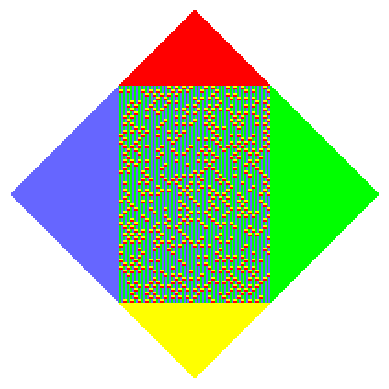

In [5]:
n = 100
a = 0
b = 1
c = 0
w = np.array([[1,0,0,1],
              [0,1,0,0],
              [0,0,1,0],
              [1,0,0,1]])


%matplotlib inline
#%matplotlib qt
A = RT.Aztec(n,w)
A.shuffle()
M = A.get_edge_matrix()
A.plot()

In [14]:
A = RT.Aztec(n,[[1,0],[0,1]])
A.shuffle()
M = A.get_edge_matrix()

In [6]:
%matplotlib qt
W,E = weight(n,w)
sampler = Glauber(W, E, M, fac=1)
viewer = PatchViewer(sampler)
plt.show(block=False)

In [ ]:
while True:
    rectangles = sampler.sweep()
    viewer.update(rectangles)
    viewer.canvas.flush_events()

# Sign Matrix

In [319]:
"""Convert the library's Aztec edge matrix to staggered block signs."""

import numpy as np


def sign_matrix(M):
    """Return block edge counts minus one, with short rows padded on the right.

    M must be a valid binary 2n by 2n Aztec edge matrix. The output is
    int8 with shape (2n-1, n), in the same top-to-bottom row order as M.
    Even output rows use even-column block origins; odd rows use odd
    origins and have a final padding zero. Signs are +1 for two occupied
    edges, 0 for one, and -1 for none. Full tiling validity is assumed.
    """
    M = np.asarray(M)
    if (M.ndim != 2 or M.shape[0] != M.shape[1]
            or M.shape[0] < 2 or M.shape[0] % 2):
        raise ValueError('M must be a nonempty square matrix of even side length')
    if not np.all((M == 0) | (M == 1)):
        raise ValueError('M must contain only 0 and 1')
    # Signed arithmetic is needed for both Boolean and unsigned inputs.
    M = M.astype(np.int8, copy=False)
    n = M.shape[0] // 2
    S = np.zeros((2*n - 1, n), dtype=np.int8)
    S[0::2, :] = (M[0::2, 0::2] + M[0::2, 1::2]
                  + M[1::2, 0::2] + M[1::2, 1::2] - 1)
    S[1::2, :-1] = (M[1:-1:2, 1:-1:2] + M[1:-1:2, 2::2]
                    + M[2::2, 1:-1:2] + M[2::2, 2::2] - 1)
    return S


In [342]:
%matplotlib inline
%matplotlib qt
plt.imshow(sign_matrix(M)[1::2])
plt.show()

# Glauber Single

In [210]:
"""Single-block Aztec Glauber dynamics and partial Matplotlib redraws.

Requires NumPy and Matplotlib. Intended for import from a Jupyter notebook.
W, E are ORIGINAL edge weights, not the reduced shuffling arrays C, E.
An edge has weight W[i,j] * epsilon**E[i,j], epsilon -> 0+.
Inputs are copied; a valid initial tiling M is required.
Use a blitting GUI backend, e.g. QtAgg or TkAgg (not inline/ipympl).
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.image import AxesImage
from matplotlib.transforms import Bbox


def comp_prop_log(w, x, y, z, ew, ex, ey, ez):
    """Library _core.comp_prop_log formula; w,x,y,z are LOG weights."""
    if ex + ey > ew + ez:
        return 0.0
    if ex + ey < ew + ez:
        return -np.inf
    return w + z - np.logaddexp(w + z, x + y)


def masks(fac):
    """The existing rasterizer's two masks, with the upward boundary rule."""
    s = 2 * fac
    r, c = np.indices((3*s, 3*s))
    u, v = 2*c + 1 - 3*s, 3*s - 2*r - 1
    a, b = u + v, u - v
    return ((-2*s <= a) & (a < 2*s) & (-4*s < b) & (b <= 4*s),
            (-4*s <= a) & (a < 4*s) & (-2*s < b) & (b <= 2*s))


class Glauber:
    def __init__(self, W, E, M, fac=1, seed=None, probability_log=comp_prop_log):
        """Optionally pass the library's actual _core.comp_prop_log callable."""
        W, E, M = np.asarray(W), np.asarray(E), np.asarray(M)
        if (M.ndim != 2 or M.shape[0] != M.shape[1] or
                M.shape[0] < 2 or M.shape[0] % 2 or
                W.shape != M.shape or E.shape != M.shape):
            raise ValueError('W, E, M must have the same nonempty 2n by 2n shape')
        if not np.all((M == 0) | (M == 1)):
            raise ValueError('M must contain 0 and 1')
        if np.iscomplexobj(W) or not np.all(np.isfinite(W)) or np.any(W < 0):
            raise ValueError('W must contain finite nonnegative real coefficients')
        if not np.all(np.isfinite(E)) or not np.all(E == np.floor(E)):
            raise ValueError('E must contain integer exponents')
        if np.any(np.abs(E) > 1_000_000_000):
            raise ValueError('Exponent magnitude must be at most 1e9')
        if isinstance(fac, bool) or not isinstance(fac, (int, np.integer)) or fac < 1:
            raise ValueError('fac must be a positive integer')
        self.M = M.astype(np.int8, copy=True)
        W = W.astype(float, copy=True)
        E = E.astype(np.int32, copy=True)
        # Same literal-zero normalization as _core.reduce_weight, without reduction.
        E[W == 0] += 1
        W[W == 0] = 1
        logW = np.log(W)
        self.rng = np.random.default_rng(seed)
        self.s = 2 * fac
        self.masks = masks(fac)
        side = self.s * (len(M) + 2)
        self.image = np.zeros((side, side), dtype=np.int8)
        for y, x in zip(*np.nonzero(self.M)):
            self.stamp(y, x)
        # Probabilities depend only on the fixed weights, so compute them once.
        self.groups = []
        for parity in (0, 1):
            yy, xx = np.meshgrid(np.arange(parity, len(M)-1, 2),
                                 np.arange(parity, len(M)-1, 2), indexing='ij')
            p = np.empty(yy.shape)
            for ij in np.ndindex(yy.shape):
                y, x = yy[ij], xx[ij]
                p[ij] = np.exp(probability_log(
                    logW[y,x], logW[y,x+1], logW[y+1,x], logW[y+1,x+1],
                    E[y,x], E[y,x+1], E[y+1,x], E[y+1,x+1]))
            self.groups.append((yy, xx, p))

    def stamp(self, y, x):
        s = self.s
        color = (1 if y % 2 == 0 else 2) if x % 2 else (3 if y % 2 else 4)
        shape = 0 if (x+y) % 2 else 1
        self.image[s*y:s*(y+3), s*x:s*(x+3)][self.masks[shape]] = color

    def step(self):
        """Attempt ONE uniformly chosen geometric flip block.

        Select from all n*n + (n-1)*(n-1) blocks, including blocked ones.
        Return [] if blocked/unchanged, otherwise one dirty rectangle.
        No scan for flippable sites and no retries until a flip occurs.
        """
        n = len(self.M) // 2
        k = int(self.rng.integers(n*n + (n-1)*(n-1)))
        if k < n*n:
            parity, i, j = 0, k // n, k % n
        else:
            k -= n*n
            parity, i, j = 1, k // (n-1), k % (n-1)
        y, x = 2*i + parity, 2*j + parity
        M = self.M
        a, b, c, d = M[y,x], M[y,x+1], M[y+1,x], M[y+1,x+1]
        if not (a == d and b == c and a != b):
            return []
        diagonal = int(self.rng.random() < self.groups[parity][2][i,j])
        if diagonal == a:
            return []
        M[y,x] = M[y+1,x+1] = diagonal
        M[y,x+1] = M[y+1,x] = 1 - diagonal
        if diagonal:
            self.stamp(y, x)
            self.stamp(y+1, x+1)
        else:
            self.stamp(y, x+1)
            self.stamp(y+1, x)
        s = self.s
        return [(s*y, s*(y+4), s*x, s*(x+4))]


class PatchViewer:
    def __init__(self, sampler):
        self.sampler = sampler
        self.fig = plt.figure(figsize=(4, 4), dpi=100, layout='none')
        self.ax = self.fig.add_axes([0, 0, 1, 1])
        if not self.fig.canvas.supports_blit:
            plt.close(self.fig)
            raise RuntimeError('Use a blitting GUI backend: %matplotlib qt or tk, not widget/inline')
        cmap = ListedColormap(['white', '#8b1220', '#c44510', '#cc9d1c', '#411e4e'])
        self.base = self.ax.imshow(sampler.image, origin='upper', cmap=cmap,
                                   vmin=-0.5, vmax=4.5, interpolation='nearest')
        # imshow owns a copy: make it the persistent array updated by the sampler.
        sampler.image = self.base.get_array().data
        self.ax.set_axis_off()
        self.ax.set_autoscale_on(False)
        self.patch = AxesImage(self.ax, origin='upper', cmap=cmap,
                               interpolation='nearest', animated=True)
        self.patch.set_clim(-0.5, 4.5)
        self.patch.set_data(np.zeros((1, 1), dtype=np.int8))
        # Saving can include animated artists. Only expose this temporary
        # overlay during an explicit partial draw; full draws use self.base.
        self.patch.set_visible(False)
        self.ax.add_image(self.patch)
        # These artists are drawn explicitly. Do not schedule automatic GUI
        # draws halfway through configuring a temporary patch.
        self.base.stale_callback = None
        self.patch.stale_callback = None
        self.canvas = self.fig.canvas
        self._pending = []
        self.fig.canvas.draw()

    def update(self, rectangles):
        """Render only changed patches. Normal GUI redraws use the full base image."""
        self._pending.extend(rectangles)
        self.base.changed()
        # Notebook display/savefig may temporarily install a print canvas,
        # including FigureCanvasBase, which has no get_renderer(). Keep the
        # changed regions until the interactive canvas is restored.
        if self.fig.canvas is not self.canvas or self.canvas.is_saving():
            return
        if not self._pending:
            return
        renderer = self.canvas.get_renderer()
        for r0, r1, c0, c1 in dict.fromkeys(self._pending):
            self.patch.set_data(self.sampler.image[r0:r1, c0:c1])
            self.patch.set_extent((c0-.5, c1-.5, r1-.5, r0-.5))
            self.patch.set_visible(True)
            try:
                self.patch.draw(renderer)
            finally:
                self.patch.set_visible(False)
            corners = self.ax.transData.transform([[c0-.5, r0-.5], [c1-.5, r1-.5]])
            lo, hi = corners.min(axis=0), corners.max(axis=0)
            bbox = Bbox.from_extents(*(np.floor(lo)-1), *(np.ceil(hi)+1))
            self.canvas.blit(bbox)
        self._pending.clear()

    def snapshot(self):
        """Return a separate static figure of the CURRENT raster for display/save.

        In a notebook: display(viewer.snapshot()). This makes a full static
        picture on request without exporting the live animation figure.
        """
        from matplotlib.figure import Figure
        from matplotlib.backends.backend_agg import FigureCanvasAgg
        fig = Figure(figsize=(4, 4), dpi=100, layout='none')
        FigureCanvasAgg(fig)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.imshow(self.sampler.image.copy(), origin='upper',
                  interpolation='nearest', cmap=self.base.get_cmap(),
                  vmin=-0.5, vmax=4.5)
        ax.set_axis_off()
        return fig

    def run(self, interval=33):
        """Start a GUI timer: one block attempt per tick, no complete sweep."""
        def tick():
            self.update(self.sampler.step())
        self.timer = self.fig.canvas.new_timer(interval=interval)
        self.timer.add_callback(tick)
        self.fig.canvas.mpl_connect('close_event', lambda event: self.timer.stop())
        self.timer.start()
        plt.show()


def animate_glauber(W, E, M, fac=1, seed=None, probability_log=comp_prop_log):
    """Return the viewer (viewer.sampler.M is the evolving edge matrix)."""
    sampler = Glauber(W, E, M, fac, seed, probability_log)
    viewer = PatchViewer(sampler)
    viewer.run()
    return viewer



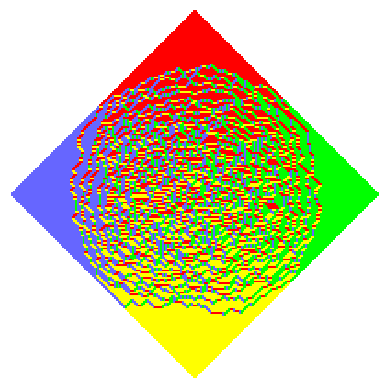

In [205]:
n = 100
w = np.array([[1,0,1,0],
              [1,1,0,0],
              [0,1,1,0]])
w = [[1]]

%matplotlib inline
A = RT.Aztec(n,w)
A.shuffle()
M = A.get_edge_matrix()
A.plot()

In [212]:
A = RT.Aztec(n,[[1,0],[0,1]])
A.shuffle()
M = A.get_edge_matrix()

In [214]:
%matplotlib qt
W,E = weight(n,w)
sampler = Glauber(W, E, M, fac=1)
viewer = PatchViewer(sampler)
plt.show(block=False)

In [232]:
while 1:
    rectangles = sampler.step()
    viewer.update(rectangles)
    viewer.canvas.flush_events()

KeyboardInterrupt: 

# Different Viewer
## Vispy

In [10]:

from vispy import app, scene
from vispy.color import Colormap

def vis_plot(M,cmap = None):
    image = aztec_image(M,1, parallel=0)

    if cmap is None:
        cmap = ['white', 'red', 'green', 'yellow', '#6666ff']

    cmap = Colormap(cmap, interpolation='zero')

    app.use_app('pyside6')

    canvas = scene.SceneCanvas(
        size=(400, 400),
        show=True,
        keys='interactive'
    )

    view = canvas.central_widget.add_view()

    img = scene.visuals.Image(
        image,
        cmap=cmap,
        clim=(-0.5, 4.5),
        interpolation='nearest',
        parent=view.scene
    )

    view.camera = scene.PanZoomCamera(aspect=1)
    view.camera.flip = (0, 1, 0)  # Origin upper
    view.camera.set_range(margin=0)

    app.run()


In [8]:
n = 100
a = 0
b = 1
c = 0
w = np.array([[1,0,0,1],
              [0,1,0,0],
              [0,0,1,0],
              [1,0,0,1]])


%matplotlib inline
#%matplotlib qt
A = RT.Aztec(n,w)
A.shuffle()
M = A.get_edge_matrix()

In [ ]:
vis_plot(M)

Qt's default DPI awareness context is DPI_AWARENESS_CONTEXT_PER_MONITOR_AWARE_V2. If you know what you are doing, you can overwrite this default using qt.conf (https://doc.qt.io/qt-6/highdpi.html#configuring-windows).


: 

# PyQT

In [4]:

import sys
import numpy as np

from PySide6.QtCore import Qt
from PySide6.QtGui import QImage, QPixmap, QColor
from PySide6.QtWidgets import (
    QApplication, QGraphicsScene, QGraphicsView, QFrame
)


class ImageViewer(QGraphicsView):
    def __init__(self, image, cmap):
        super().__init__()

        # Convert to contiguous uint8 array
        self.pixels = np.ascontiguousarray(image, dtype=np.uint8)
        height, width = self.pixels.shape

        # Create indexed image with custom colormap
        qimage = QImage(
            self.pixels.data,
            width, height,
            self.pixels.strides[0],
            QImage.Format.Format_Indexed8
        )
        qimage.setColorTable([QColor(c).rgba() for c in cmap])

        # Create pixmap
        pixmap = QPixmap.fromImage(qimage)

        scene = QGraphicsScene(self)
        item = scene.addPixmap(pixmap)
        item.setTransformationMode(
            Qt.TransformationMode.FastTransformation
        )
        self.setScene(scene)

        # Interactive viewing
        self.setDragMode(QGraphicsView.DragMode.ScrollHandDrag)
        self.setTransformationAnchor(
            QGraphicsView.ViewportAnchor.AnchorUnderMouse
        )

        # Remove axes, scrollbars and borders
        self.setHorizontalScrollBarPolicy(
            Qt.ScrollBarPolicy.ScrollBarAlwaysOff
        )
        self.setVerticalScrollBarPolicy(
            Qt.ScrollBarPolicy.ScrollBarAlwaysOff
        )
        self.setFrameShape(QFrame.Shape.NoFrame)
        self.setBackgroundBrush(QColor('white'))

    def wheelEvent(self, event):
        # Zoom using mouse wheel
        factor = 1.2 ** (event.angleDelta().y() / 120)
        self.scale(factor, factor)


def QT_plot(M,cmap = None):
    # Your original image computation
    image = aztec_image(M, 1, parallel=0)

    if cmap is None:
        cmap = ['white', 'red', 'green', 'yellow', '#6666ff']

    app = QApplication.instance() or QApplication(sys.argv)

    viewer = ImageViewer(image, cmap)
    viewer.resize(400, 400)
    viewer.show()
    viewer.fitInView(
        viewer.sceneRect(),
        Qt.AspectRatioMode.KeepAspectRatio
    )

    app.exec()


In [5]:
n = 100
a = 0
b = 1
c = 0
w = np.array([[1,0,0,1],
              [0,1,0,0],
              [0,0,1,0],
              [1,0,0,1]])


%matplotlib inline
#%matplotlib qt
A = RT.Aztec(n,w)
A.shuffle()
M = A.get_edge_matrix()

In [6]:
QT_plot(M)